# Online Retail II: sales, customers and returns

A UK online gift retailer, December 2009 to December 2011, about 1 million invoice lines
([UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii), CC BY 4.0).
Most customers are wholesalers. Prices are in pounds sterling.

Questions:

1. Is the business growing, and where does the growth come from?
2. How seasonal are sales?
3. Which products drive revenue, and which come back as returns?
4. Who are the customers, how concentrated is revenue, and do new customers come back?

Cleaning is in `src/clean.py`; every metric used here and in the dashboard is in `src/metrics.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import metrics as m

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
GBP = mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}M" if abs(x) >= 1e6 else f"£{x/1e3:.0f}K")

df = pd.read_parquet(ROOT / "data" / "processed" / "transactions.parquet")
print(f"{len(df):,} clean line items, {df['InvoiceDate'].min():%d %b %Y} to {df['InvoiceDate'].max():%d %b %Y}")

1,018,480 clean line items, 01 Dec 2009 to 09 Dec 2011


## 1. Cleaning

The raw file needed more than dropping nulls. The two Excel sheets overlap in December 2010,
some lines are postage or fees rather than products, and a handful of very large orders were
cancelled minutes after being placed. Left in, one of those (80,995 paper craft kits, £168K)
would rank as the 4th best-selling product and make December 2011 look like a returns disaster.

In [2]:
log = pd.read_csv(ROOT / "data" / "processed" / "cleaning_log.csv")
log[["step", "rows_removed", "rows_after", "note"]]

,step,rows_removed,rows_after,note
0,load,0,1067371,Both sheets combined (Dec 2009 - Dec 2011)
1,sheet_overlap,22523,1044848,Second sheet repeats invoices up to 09 Dec 201...
2,exact_duplicates,11812,1033036,"Identical rows, usually double-scanned items"
3,bad_debt_adjustments,6,1033030,Invoices starting with 'A' are accounting entries
4,non_product_codes,5812,1027218,"Postage, fees, discounts, manual entries, gift..."
5,zero_or_negative_price,5964,1021254,"Free samples, damaged-stock notes and write-offs"
6,negative_qty_not_return,0,1021254,Stock corrections that are not customer returns
7,cancelled_within_a_day,2774,1018480,1387 sales fully cancelled by the same custome...
8,missing_customer_id_kept,0,1018480,226943 rows have no Customer ID; kept for reve...


Rows without a Customer ID are kept for revenue totals but left out of customer metrics:

In [3]:
no_id_share = df.loc[df["CustomerID"].isna(), "Revenue"].sum() / df["Revenue"].sum()
print(f"Revenue on lines without a Customer ID: {no_id_share:.1%}")

Revenue on lines without a Customer ID: 13.6%


## 2. Revenue trend

Net revenue £18,927,436 | orders 39,388 | customers 5,851 | average order £490 | returns 1.9% of gross


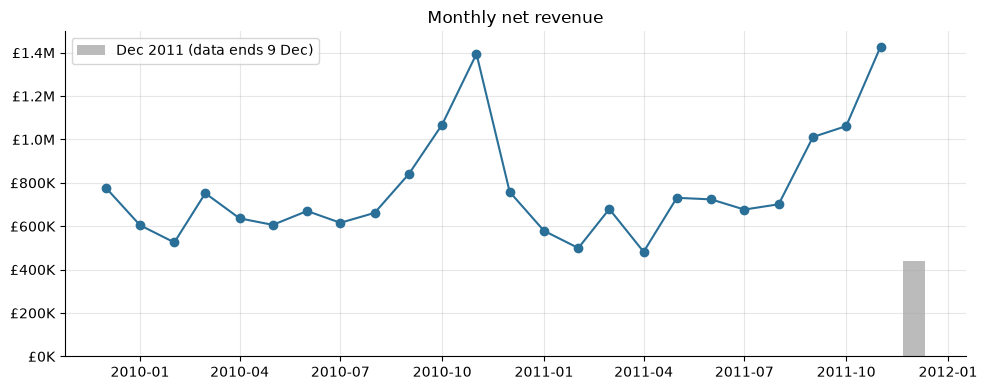

In [4]:
k = m.kpis(df)
print(f"Net revenue £{k['net_revenue']:,.0f} | orders {k['orders']:,} | customers {k['customers']:,} | "
      f"average order £{k['avg_order_value']:,.0f} | returns {k['return_rate']:.1%} of gross")

mo = m.monthly(df)
fig, ax = plt.subplots()
full, part = mo[~mo["partial_month"]], mo[mo["partial_month"]]
ax.plot(full["Month"], full["net_revenue"], marker="o", color="#2a6f97")
ax.bar(part["Month"], part["net_revenue"], width=20, color="#bbbbbb", label="Dec 2011 (data ends 9 Dec)")
ax.yaxis.set_major_formatter(GBP)
ax.set_title("Monthly net revenue")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "monthly_revenue.png", dpi=150)

December 2011 only covers nine days, so the comparison below uses January to November of each year.

In [5]:
def period(year):
    p = mo[(mo["Month"].dt.year == year) & (mo["Month"].dt.month <= 11)]
    return pd.Series({"net_revenue": p["net_revenue"].sum(), "orders": p["orders"].sum(),
                      "gross_revenue": p["gross_revenue"].sum()})

yoy = pd.DataFrame({"Jan-Nov 2010": period(2010), "Jan-Nov 2011": period(2011)}).T
yoy["avg_order_value"] = yoy["gross_revenue"] / yoy["orders"]
change = yoy.loc["Jan-Nov 2011"] / yoy.loc["Jan-Nov 2010"] - 1
print("Change, Jan-Nov 2011 vs 2010: " + ", ".join(f"{c} {change[c]:+.1%}" for c in ["net_revenue", "orders", "avg_order_value"]))
yoy[["net_revenue", "orders", "avg_order_value"]]

Change, Jan-Nov 2011 vs 2010: net_revenue +2.3%, orders -3.7%, avg_order_value +6.2%


,net_revenue,orders,avg_order_value
Jan-Nov 2010,"8,377,774.41","18,018.00",474.15
Jan-Nov 2011,"8,572,828.10","17,352.00",503.53


Revenue grew slightly while the number of orders fell, so the growth came from larger orders.
Where did the customers go? Counting customers by the month of their first order in the data:

In [6]:
sales = df[~df["IsReturn"]].dropna(subset=["CustomerID"])
first = sales.groupby("CustomerID")["Month"].min()
new = first[first.dt.month <= 11].groupby(first.dt.year).size().loc[[2010, 2011]]
print(f"First-time customers, Jan-Nov: 2010 = {new[2010]:,}, 2011 = {new[2011]:,} ({new[2011] / new[2010] - 1:+.0%})")

First-time customers, Jan-Nov: 2010 = 3,285, 2011 = 1,511 (-54%)


Caveat: the data starts in December 2009, so some "first-time" customers in early 2010 had bought
before. That inflates the 2010 count somewhat, but the gap is too large to be explained by that alone:
in 2011, every month from January to November brought fewer new customers than the same month in 2010.

## 3. Seasonality

In [7]:
for year in (2010, 2011):
    p = mo[(mo["Month"].dt.year == year) & (mo["Month"].dt.month <= 11)]
    autumn = p[p["Month"].dt.month.isin([9, 10, 11])]["net_revenue"].sum()
    print(f"{year}: September-November = {autumn / p['net_revenue'].sum():.0%} of January-November revenue")

2010: September-November = 39% of January-November revenue
2011: September-November = 41% of January-November revenue


## 4. Products and returns

,Description,revenue,units,orders
0,REGENCY CAKESTAND 3 TIER,"328,459.72",26290,3903
1,WHITE HANGING HEART T-LIGHT HOLDER,"258,779.83",93785,5459
2,JUMBO BAG RED RETROSPOT,"181,334.55",96410,4003
3,PARTY BUNTING,"148,270.58",28190,2672
4,ASSORTED COLOUR BIRD ORNAMENT,"128,989.40",79861,2802
5,PAPER CHAIN KIT 50'S CHRISTMAS,"116,773.64",34677,2012
6,CHILLI LIGHTS,"80,104.93",15740,1131
7,SMALL POPCORN HOLDER,"79,367.70",88289,2320
8,JUMBO BAG PINK POLKADOT,"75,560.12",39007,2240
9,ROTATING SILVER ANGELS T-LIGHT HLDR,"71,300.40",31409,756


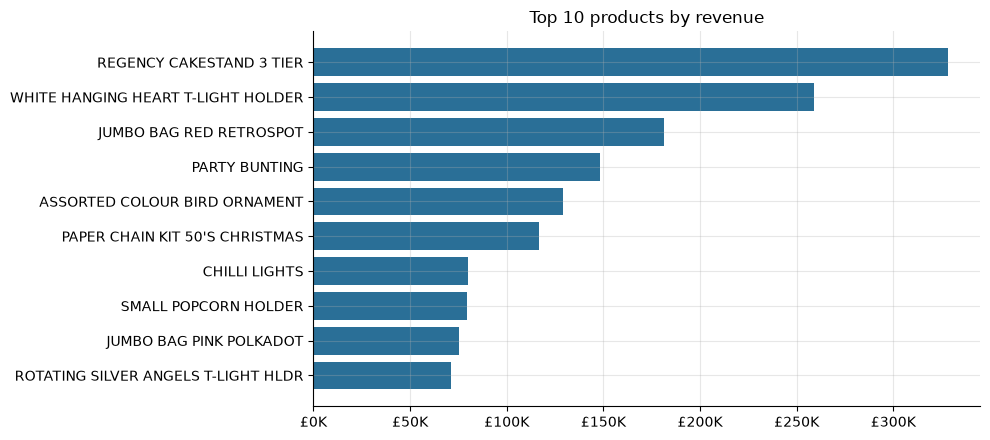

In [8]:
top = m.top_products(df, 10)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top["Description"][::-1], top["revenue"][::-1], color="#2a6f97")
ax.xaxis.set_major_formatter(GBP)
ax.set_title("Top 10 products by revenue")
fig.tight_layout(); fig.savefig(FIG / "top_products.png", dpi=150)
top

Return rates by product, among products with at least £5,000 of sales:

In [9]:
m.most_returned(df, 8).style.format({"sold": "£{:,.0f}", "returned": "£{:,.0f}", "return_share": "{:.0%}"})

,Description,sold,returned,return_share
0,SMALL FAIRY CAKE FRIDGE MAGNETS,"£6,875","£3,646",53%
1,WHITE CHERRY LIGHTS,"£17,918","£6,290",35%
2,LOVE GARLAND PAINTED ZINC,"£5,699","£1,858",33%
3,LIGHT PINK CHERRY LIGHTS,"£8,350","£2,572",31%
4,PINK CHERRY LIGHTS,"£13,657","£3,891",28%
5,FAIRY CAKE FLANNEL ASSORTED COLOUR,"£25,369","£6,577",26%
6,FRENCH WC SIGN BLUE METAL,"£5,511","£1,341",24%
7,TWO DOOR CURIO CABINET,"£11,113","£2,536",23%


## 5. Countries

In [10]:
m.country_revenue(df).head(8).style.format({"net_revenue": "£{:,.0f}", "share": "{:.1%}"})

,Country,net_revenue,customers,share
0,United Kingdom,"£16,168,943",5357,85.5%
1,Ireland,"£603,117",3,3.2%
2,Netherlands,"£546,095",22,2.9%
3,Germany,"£374,574",107,2.0%
4,France,"£293,431",93,1.6%
5,Australia,"£166,282",15,0.9%
6,Switzerland,"£92,918",22,0.5%
7,Spain,"£84,812",38,0.4%


## 6. Customers

Customers are scored 1 to 5 on recency, frequency and monetary value (quintiles), then grouped
into named segments. Reference date: the day after the last invoice.

,segment,customers,revenue,avg_recency_days,avg_orders,customer_share,revenue_share
0,Champions,1469,"£11,506,155",20,15.6,25%,70%
1,Loyal,506,"£1,596,393",105,8.4,9%,10%
2,Potential loyalists,715,"£630,716",26,2.6,12%,4%
3,New,172,"£58,577",30,1.0,3%,0%
4,Needs attention,641,"£526,625",109,2.1,11%,3%
5,At risk,823,"£1,428,232",367,5.0,14%,9%
6,Hibernating,1508,"£614,886",456,1.3,26%,4%


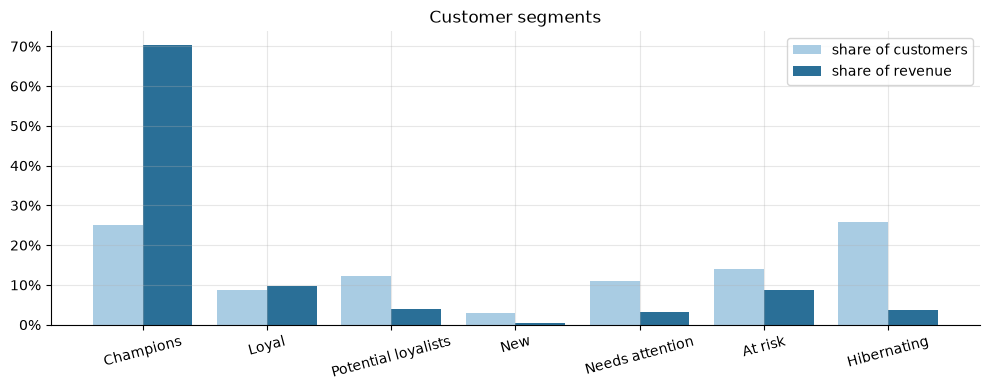

In [11]:
rfm = m.rfm(df)
seg = m.segment_summary(rfm)
fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(seg))
ax.bar([i - 0.2 for i in x], seg["customer_share"], width=0.4, label="share of customers", color="#a9cce3")
ax.bar([i + 0.2 for i in x], seg["revenue_share"], width=0.4, label="share of revenue", color="#2a6f97")
ax.set_xticks(list(x), seg["segment"], rotation=15)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Customer segments")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "segments.png", dpi=150)
seg.style.format({"revenue": "£{:,.0f}", "avg_recency_days": "{:.0f}", "avg_orders": "{:.1f}",
                  "customer_share": "{:.0%}", "revenue_share": "{:.0%}"})

In [12]:
known = df.dropna(subset=["CustomerID"])
per_customer = known.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
per_customer = per_customer[per_customer > 0]
top10 = per_customer.head(len(per_customer) // 10).sum() / per_customer.sum()
orders = known[~known["IsReturn"]].groupby("CustomerID")["Invoice"].nunique()
print(f"Top 10% of customers: {top10:.0%} of revenue")
print(f"Customers who ordered only once: {(orders == 1).mean():.0%}")

Top 10% of customers: 63% of revenue
Customers who ordered only once: 28%


### Do new customers come back?

Share of each first-purchase cohort that ordered again N months later. The December 2009 cohort
is everyone already buying when the data starts, so it looks better than true new customers.

Ordering again the next month: 2010 cohorts 20%, 2011 cohorts 23%, December 2010 cohort 9%


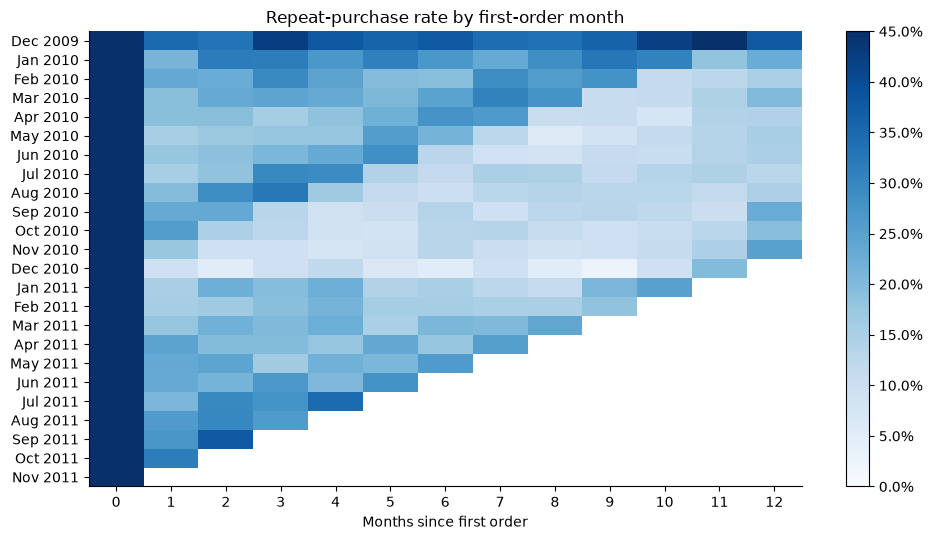

In [13]:
ret = m.cohort_retention(df)
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(ret.values, cmap="Blues", vmin=0, vmax=0.45, aspect="auto")
ax.set_yticks(range(len(ret)), [d.strftime("%b %Y") for d in ret.index])
ax.set_xticks(range(ret.shape[1]), ret.columns)
ax.set_xlabel("Months since first order"); ax.grid(False)
ax.set_title("Repeat-purchase rate by first-order month")
fig.colorbar(im, format=mtick.PercentFormatter(1.0))
fig.tight_layout(); fig.savefig(FIG / "cohorts.png", dpi=150)
c10, c11 = ret.loc["2010-01-01":"2010-11-01"], ret.loc["2011-01-01":"2011-10-01"]
print(f"Ordering again the next month: 2010 cohorts {c10[1].mean():.0%}, 2011 cohorts {c11[1].mean():.0%}, "
      f"December 2010 cohort {ret.loc['2010-12-01', 1]:.0%}")

# Summary of findings

Online Retail II, a UK online gift retailer that sells mostly to wholesalers. December 2009 to
9 December 2011, £18.9M net revenue, 39,388 orders, 5,851 identified customers.
Full analysis: `notebooks/analysis.ipynb`.

## What the data shows

**1. Revenue held up because existing customers spent more, while new-customer numbers halved.**
Comparing January to November, 2011 revenue was 2.3% higher than 2010, but there were 3.7% fewer
orders. The average order grew 6.2%, from £474 to £504. Over the same months the shop gained
1,511 first-time customers in 2011 against 3,285 in 2010. Part of the 2010 figure is customers who
had bought before the data starts, but every single month of 2011 brought in fewer new customers than
the same month a year earlier.

**2. Two-fifths of the year's revenue arrives in September to November.**
September, October and November made up 39% of January-November revenue in 2010 and 41% in 2011.
November is the peak month in both years (£1.39M and £1.43M).

**3. A quarter of customers bring in 70% of revenue.**
The "Champions" segment (recent and frequent buyers) is 25% of customers and 70% of revenue.
The top 10% of customers alone account for 63%. Three customers in Ireland generate 3.2% of all
revenue.

**4. 823 lapsed customers used to spend a lot.**
The "At risk" segment averaged 5 orders and £1.43M in total, but on average had not ordered for a
year by the end of the data.

**5. Only about one new customer in five orders again the following month.**
The rate was 20% for 2010 cohorts and 23% for 2011 cohorts. Customers first acquired in December
2010 came back least (9%). 28% of all customers ordered only once.

**6. Returns are low overall but concentrated in a few products.**
After removing orders cancelled within a day, returns are 1.9% of gross sales. A few lines are far
higher: the cherry lights range has 28-35% of sales returned, and small fairy cake fridge magnets 53%.

## Recommendations

1. **Find out why new-customer numbers fell in 2011** (marketing spend, channel, pricing, a lost
   marketplace) before planning next year's targets. Current growth depends on a small group of
   existing buyers.
2. **Win back the At-risk segment** with a targeted offer ahead of the September-November peak. If
   one in ten of them came back and spent what they spent over these two years, that is about £140K.
3. **Look after the largest accounts.** With 63% of revenue from the top 10% of customers, losing a
   few of them would show up immediately. A named contact and early access to the autumn range are
   cheap ways to protect them.
4. **Plan stock and staffing around September to November**, when about 40% of revenue arrives.
5. **Check the high-return products** (cherry lights, fridge magnets) for quality or description
   problems with the supplier.
6. **Record a customer ID on every order.** 13.6% of revenue has none, which limits any customer-level
   analysis.

## Limits of this analysis

- December 2011 contains only nine days and is left out of trend and cohort comparisons.
- Customers who bought before December 2009 cannot be told apart from new customers in early 2010.
- Segment boundaries are quintiles, so they describe customers relative to each other, not against a
  fixed target.
